# A treated cohort

Xenium sections from skin tumours before and after anti-PD-1 treatment,
analysed as one cohort, and reduced to a feature vector per sample that can
be compared across timepoints.

Three things shape everything below.

**The samples are analysed together.** All sections are adapted and encoded
in one run, so the prototypes and the niche clustering are shared. That is
what makes niche 4 mean the same thing in a pre-treatment and a
post-treatment section, which is the precondition for comparing them at
all.

**Each sample gets its own interaction graph.** The co-expression component
is measured per section, so the attention can differ between them. With one
graph for the cohort every sample would contribute identical interaction
scores.

**The unit of analysis is the sample, not the cell.** Each section is
reduced to a composition vector over niches and a vector of interaction
scores, and those are what any downstream comparison sees.

The sections are already preprocessed, so this notebook starts from the
`.pt` files.

## 1. Setup

In [8]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import anndata as ad
from pathlib import Path

# --- edit these -------------------------------------------------------
PT_DIR     = "/DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/treatment_pre_post"
VOCAB_PATH = "/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json"
CHECKPOINT = "/DATA1/Roxana/Hierarchy/Two_levels/hebi_foundation_best_new.pt"
WORK_DIR   = Path("./results/skin_pre_post")
# ----------------------------------------------------------------------

LABEL_COLS = ["timepoint", "tissue"]

NUM_DOMAINS     = 15     # Level-2 niche prototypes
NUM_NICHES      = 12     # cell-level clusters on z0
COMP_NUM_NICHES = 12     # composition niches, the feature dimension
NUM_EPOCHS      = 15
LR              = 1e-4
SEED            = 2025
DEVICE          = "cuda:0"

# Every sample is held in memory during encoding. Run a few first and
# confirm the feature blocks look right before the full cohort.
MAX_SAMPLES = []         # None for all

H5AD_DIR = WORK_DIR / "h5ad"
OUT_DIR  = WORK_DIR / "results"
H5AD_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

section_files = sorted(os.path.basename(p)
                       for p in glob.glob(os.path.join(PT_DIR, "*.pt")))
if MAX_SAMPLES:
    section_files = section_files[:MAX_SAMPLES]
sample_ids = [f.replace(".pt", "") for f in section_files]

print(f"{len(section_files)} samples in {PT_DIR}")

12 samples in /DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/treatment_pre_post


## 2. Samples as AnnData

The `.pt` holds the graph, the METIS partition and the expression matrix,
but the pipeline reads expression and coordinates from an AnnData. So the
AnnData is rebuilt from the `.pt` and written out. This is not
preprocessing and nothing is recomputed: coordinates come straight from the
`.pt`, so the coordinate alignment the pipeline performs is a check rather
than a correction.

Labels travel alongside. They live either in a `labels` dict inside the
`.pt` or as top-level keys, depending on when the sections were built, so
both are tried.

In [2]:
def build_sample_adata(pt_dir, files, label_cols, h5ad_dir):
    """One AnnData per sample, written to disk, plus its label row."""
    paths, labels = [], []

    for f in files:
        d = torch.load(os.path.join(pt_dir, f), map_location="cpu",
                       weights_only=False)

        X = d["X"]
        X = X.float().numpy() if torch.is_tensor(X) else np.asarray(X, float)
        coords = d["coords"]
        coords = coords.numpy() if torch.is_tensor(coords) else np.asarray(coords)

        a = ad.AnnData(X=X)
        a.var_names = [str(g) for g in d["gene_names"]]
        a.var_names_make_unique()
        a.obsm["spatial"] = np.asarray(coords, dtype=float)

        sid = str(d.get("sample_id", f.replace(".pt", "")))
        row = {"sample_id": sid,
               "patient_id": str(d.get("patient_id", "unknown"))}
        d_labels = d.get("labels", {})
        for c in label_cols:
            val = d_labels.get(c, d.get(c, np.nan))
            row[c] = "nan" if pd.isna(val) else str(val)

        out = Path(h5ad_dir) / f"{sid}.h5ad"
        a.write_h5ad(out)
        paths.append(str(out))
        labels.append(row)

    return paths, pd.DataFrame(labels)


h5ad_files, label_df = build_sample_adata(
    PT_DIR, section_files, LABEL_COLS, H5AD_DIR
)
print(label_df.to_string(index=False))

                  sample_id patient_id timepoint tissue
 su001_Post_PostTumor1_rep2      su001      Post  Tumor
 su001_Post_PostTumor2_rep2      su001      Post  Tumor
 su001_Post_PostTumor3_rep2      su001      Post  Tumor
 su001_Post_PostTumor4_rep2      su001      Post  Tumor
 su001_Post_PostTumor5_rep2      su001      Post  Tumor
 su001_Post_PostTumor6_rep2      su001      Post  Tumor
   su001_Pre_PreTumor1_rep2      su001       Pre  Tumor
   su001_Pre_PreTumor2_rep2      su001       Pre  Tumor
su002_Post_Tumor_GSM8831646      su002      Post  Tumor
 su002_Pre_Tumor_GSM8831645      su002       Pre  Tumor
su007_Post_Tumor_GSM8831638      su007      Post  Tumor
 su007_Pre_Tumor_GSM8831647      su007       Pre  Tumor


Two things to check before encoding.

The state of the matrix decides `preprocess` below. The pipeline normalises
and logs the AnnData in memory because the GRN stage reads expression from
it, which is right for raw counts and wrong for a matrix that has already
been through it.

The label balance decides what any comparison can say. With a handful of
samples per timepoint, a difference between pre and post is a description
of these sections, not an inference about treatment.

In [3]:
a0 = ad.read_h5ad(h5ad_files[0])
block = a0.X[:500]
block = block.toarray() if hasattr(block, "toarray") else np.asarray(block)
integral = np.allclose(block, np.round(block))
print(f"{a0.n_obs:,} cells, {a0.n_vars} genes in the first sample")
print("X looks like:", "raw counts" if integral else "already transformed",
      f"(max {block.max():.2f})")
del a0, block

print()
for c in LABEL_COLS:
    print(f"{c}: " + "  ".join(
        f"{k}={v}" for k, v in label_df[c].value_counts().items()))
print("patients:", label_df.patient_id.nunique())

42,786 cells, 478 genes in the first sample
X looks like: already transformed (max 8.13)

timepoint: Post=8  Pre=4
tissue: Tumor=12
patients: 3


## 3. Encoding the cohort

`per_section_grn=True` builds one interaction graph per sample, which is
what lets the attention vary between them. The curated priors are the same
in every graph; the co-expression edges are measured per section, so the
graphs differ and only their shared edges can be compared, which is what
the next section handles.

In [13]:
from hebi.inference.pipeline import encode_sections, cluster_sections

PREPROCESS = False        # set False if the check above said "already transformed"

sections, ctx = encode_sections(
    checkpoint_path=CHECKPOINT,
    data_dir=PT_DIR,
    section_files=section_files,
    h5ad_files=h5ad_files,
    vocab_path=VOCAB_PATH,
    section_labels=sample_ids,

    mode="continual",
    init="random",
    num_epochs=NUM_EPOCHS,
    lr=LR,

    grn=True,
    per_section_grn=True,
    species="Human",

    preprocess=PREPROCESS,
    output_dir=str(OUT_DIR),
    device=DEVICE,
    seed=SEED,
)
print(f"\n{len(sections)} samples encoded")

Seed set to 2025
Loading results/skin_pre_post/h5ad/su001_Post_PostTumor1_rep2.h5ad
Covered genes: 478/478 (100.00%)
  42786 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Post_PostTumor2_rep2.h5ad
Covered genes: 478/478 (100.00%)
  56310 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Post_PostTumor3_rep2.h5ad
Covered genes: 478/478 (100.00%)
  13084 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Post_PostTumor4_rep2.h5ad
Covered genes: 478/478 (100.00%)
  9684 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Post_PostTumor5_rep2.h5ad
Covered genes: 478/478 (100.00%)
  11700 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Post_PostTumor6_rep2.h5ad
Covered genes: 478/478 (100.00%)
  17338 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Pre_PreTumor1_rep2.h5ad
Covered genes: 478/478 (100.00%)
  5684 cells, 478 genes
Loading results/skin_pre_post/h5ad/su001_Pre_PreTumor2_rep2.h5ad
Covered genes: 478/478 (100.00%)
  3898 cells, 

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


   [cache-write] updated local cache for 'pathwayextra': 48764 rows
   Fetching 'ligrecextra' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'ligrecextra': 6658 rows
   Fetching 'dorothea' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'dorothea': 15267 rows
   Computing data-driven Spearman edges...
   [info] input already log-scale (max=8.27) -- skipping normalize_total/log1p to avoid double-normalizing
   Constructing PyG graph with directed edge typing...
✅ Directed GRN built! Nodes: 478, Edges: 955
   Pathway edges:  692
   Spearman edges: 230
   LigRec edges:   76
   TF edges:       39
🧬 Building directed heterogeneous GRN (Species: Human)...
   Fetching curated priors (Pathway, LigRec, TF-Target)...
   Fetching 'pathwayextra' from OmniPath web API (whole dataset)...


/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


   [cache-write] updated local cache for 'pathwayextra': 48764 rows
   Fetching 'ligrecextra' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'ligrecextra': 6658 rows
   Fetching 'dorothea' from OmniPath web API (whole dataset)...
   [cache-write] updated local cache for 'dorothea': 15267 rows
   Computing data-driven Spearman edges...
   [info] input already log-scale (max=8.45) -- skipping normalize_total/log1p to avoid double-normalizing
   Constructing PyG graph with directed edge typing...
✅ Directed GRN built! Nodes: 478, Edges: 926
   Pathway edges:  692
   Spearman edges: 197
   LigRec edges:   76
   TF edges:       39
🧬 Building directed heterogeneous GRN (Species: Human)...
   Fetching curated priors (Pathway, LigRec, TF-Target)...
   Fetching 'pathwayextra' from OmniPath web API (whole dataset)...


/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


... (39 outputs left out)

Encoding /DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/treatment_pre_post/su


📦 Loading preprocessed slide from /DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/treatment_pre_post/su007_Pre_Tumor_GSM8831647.pt
✅ Loaded data: X=torch.Size([48149, 478]), coords=torch.Size([48149, 2]), edge_index=torch.Size([2, 277392])


Encoding /DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/treatment_pre_post/su

  256,566 cells encoded; 20/20 prototypes in use

12 samples encoded


## 4. Niches shared across samples

Clustering runs over every sample at once, so a niche label means the same
thing everywhere.

`n_composition_niches` is the dimension of the composition feature below,
so it is a modelling choice rather than a display setting: too few and
samples become indistinguishable, too many and each niche is too rare for
its proportion to be estimated from one section.

In [14]:
written = cluster_sections(
    sections, ctx,
    n_cell_clusters=NUM_NICHES,
    n_composition_niches=COMP_NUM_NICHES,
    composition_neighbors=200,
    cluster_method="kmeans",
    point_size=4,
)
niche_key = written["composition_niches"]
cell_key  = written["cell_clusters"]
print("\nniche column:", niche_key)
print("cell column: ", cell_key)


Cell-level clustering: kmeans, k=12  ->  obs['z0_kmeans_12']
Niche-level clustering: 12 niches from 200-neighbour composition  ->  obs['comp_niches_12']

su001_Post_PostTumor1_rep2
  z0_kmeans_12           FIDE=0.5742
  prototypes             FIDE=0.6373
  comp_niches_12         FIDE=0.9561
su001_Post_PostTumor2_rep2
  z0_kmeans_12           FIDE=0.5822
  prototypes             FIDE=0.6466
  comp_niches_12         FIDE=0.9575
su001_Post_PostTumor3_rep2
  z0_kmeans_12           FIDE=0.6577
  prototypes             FIDE=0.7008
  comp_niches_12         FIDE=0.9589
su001_Post_PostTumor4_rep2
  z0_kmeans_12           FIDE=0.8927
  prototypes             FIDE=0.8358
  comp_niches_12         FIDE=0.9712
su001_Post_PostTumor5_rep2
  z0_kmeans_12           FIDE=0.6875
  prototypes             FIDE=0.6654
  comp_niches_12         FIDE=0.9617
su001_Post_PostTumor6_rep2
  z0_kmeans_12           FIDE=0.6353
  prototypes             FIDE=0.7191
  comp_niches_12         FIDE=0.9492
su001_Pre_PreTumo

One figure per sample, not one canvas for the cohort. A combined plot of
every cell in every section runs to gigabytes and is unreadable at any
size that fits on a page; separate panels stay small and can actually be
compared side by side.

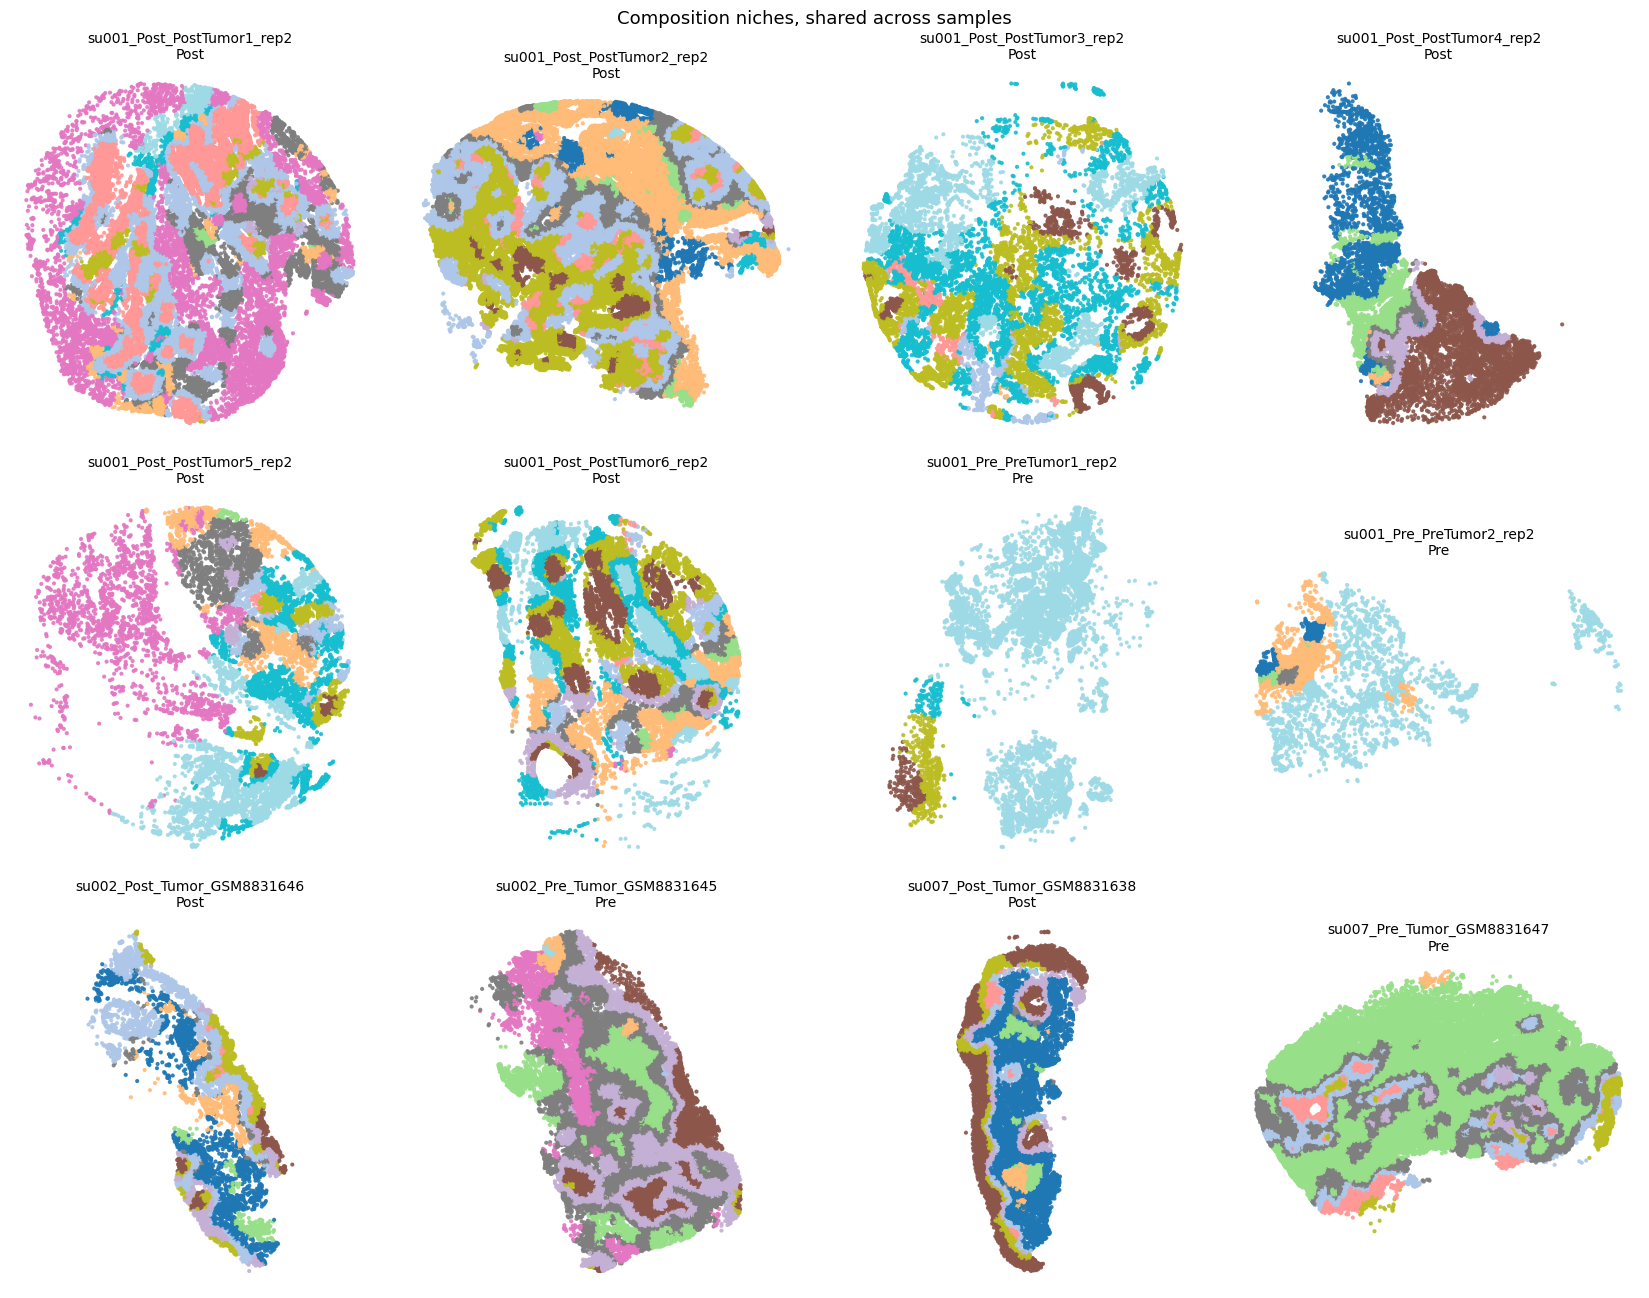

In [15]:
import matplotlib.pyplot as plt


def plot_sample_labels(coords, label_arr, title, n_labels, ax, s=4):
    ax.scatter(coords[:, 0], coords[:, 1], c=label_arr, cmap="tab20",
               s=s, alpha=0.85, vmin=0, vmax=max(n_labels - 1, 1),
               rasterized=True)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")


def plot_cohort(sections, label_df, key, n_labels, suptitle, save_stem=None):
    n = len(sections)
    ncols = min(4, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 4.4 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, a, (_, row) in zip(axes, sections, label_df.iterrows()):
        plot_sample_labels(
            np.asarray(a.obsm["spatial"]),
            a.obs[key].astype(int).values,
            f"{row.sample_id}\n{row[LABEL_COLS[0]]}",
            n_labels, ax,
        )
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout()
    if save_stem:
        for ext in (".svg", ".png"):
            fig.savefig(Path(save_stem).with_suffix(ext),
                        bbox_inches="tight", dpi=200 if ext == ".png" else None)
    plt.show()


plot_cohort(sections, label_df, niche_key, COMP_NUM_NICHES,
            "Composition niches, shared across samples",
            save_stem=OUT_DIR / "niches_by_sample")

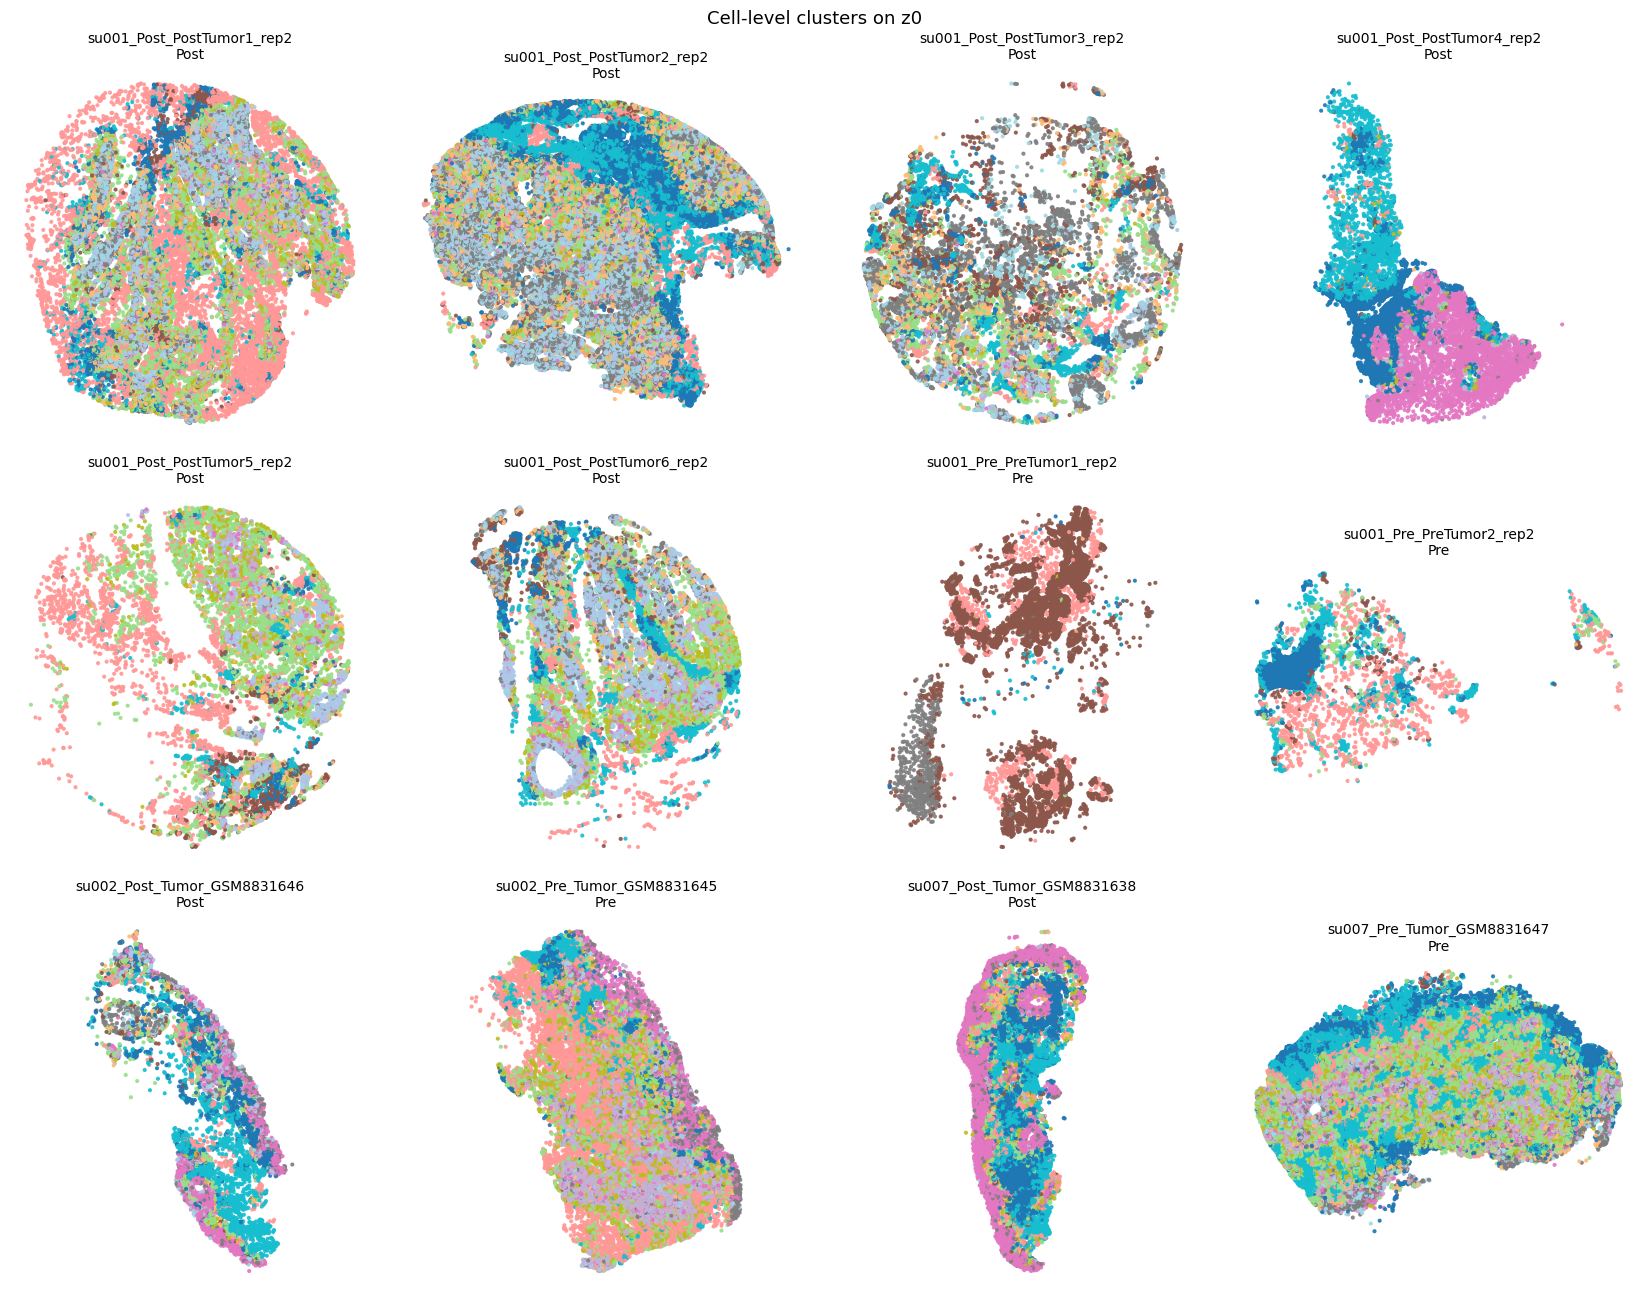

In [16]:
plot_cohort(sections, label_df, cell_key, NUM_NICHES,
            "Cell-level clusters on z0",
            save_stem=OUT_DIR / "z0_clusters_by_sample")

## 5. Interactions shared across samples

A feature vector needs identical columns in every sample, so the analysis
is restricted to the edges present in all of them.

`shared_curated_edges` returns, for each sample, the positions of those
shared edges within that sample's own edge list, together with one list of
edge labels. The positions differ per sample because edge ordering does;
the labels are the shared column names.

In [17]:
from hebi.grn.build_ppi_codex import shared_curated_edges

gene_graph_list = ctx["gene_graph_list"]
gene_names      = ctx["gene_names_list"][0]

positions, edge_labels = shared_curated_edges(gene_graph_list, gene_names)
n_shared = len(edge_labels)
print(f"shared edges across {len(sections)} samples: {n_shared}")

shared edges across all regions: 735
shared edges across 12 samples: 735


## 6. Sample-level features

Two feature blocks per sample.

**Composition** is the fraction of cells in each niche. Fractions, not
counts: sections differ in size, and counts would make a classifier read
section area.

**Interaction scores** combine the learned attention with expression. For
edge *e* and niche *c*, the score is the attention on *e* times the mean
expression of its two genes among the cells of niche *c*. A niche absent
from a sample contributes zeros, which is the correct encoding of absence
rather than a missing value.

The flat block keeps every niche by edge combination. The compact block
averages over niches, giving one value per edge, which is far smaller and
worth having when the sample count is small relative to the feature count.

In [18]:
def region_features(attn, edge_index, X, niche_labels, positions, n_niches):
    """Interaction scores for one sample.

    Returns (flat [n_niches * n_shared], niche_mean [n_shared]).
    score(e, c) = attention(e) * mean_expr_c(source) * mean_expr_c(target)
    """
    attn = np.asarray(attn, dtype=float).reshape(-1)
    ei   = np.asarray(edge_index)
    X    = np.asarray(X, dtype=float)
    nl   = np.asarray(niche_labels)

    pos = np.asarray(positions, dtype=int)
    src, dst, a = ei[0, pos], ei[1, pos], attn[pos]

    mat = np.zeros((n_niches, len(pos)), dtype=float)
    for c in range(n_niches):
        m = nl == c
        if not m.any():
            continue                      # niche absent from this sample
        e = X[m].mean(0)
        mat[c] = a * e[src] * e[dst]

    return mat.reshape(-1), mat.mean(0)


def composition_vector(niche_labels, n_niches):
    """Fractions, not counts, so section size is not a feature."""
    nl = np.asarray(niche_labels)
    v = np.bincount(nl[nl >= 0], minlength=n_niches).astype(float)
    return v / v.sum() if v.sum() > 0 else v


def zscore(M):
    mu, sd = M.mean(0), M.std(0)
    sd[sd < 1e-8] = 1.0
    return (M - mu) / sd

In [19]:
grn_attention = ctx["grn_attention"]

Xc, Xf, Xm, kept = [], [], [], []

for i, a in enumerate(sections):
    attn = grn_attention[i]
    if attn is None:
        print(f"  {sample_ids[i]}: no attention, skipping sample")
        continue

    nl = a.obs[niche_key].astype(int).values
    Xdata = a.X.toarray() if hasattr(a.X, "toarray") else np.asarray(a.X)

    flat, nmean = region_features(
        attn.detach().cpu().numpy() if torch.is_tensor(attn) else np.asarray(attn),
        gene_graph_list[i]["global"].edge_index.cpu().numpy(),
        Xdata, nl, positions[i], COMP_NUM_NICHES,
    )

    Xc.append(composition_vector(nl, COMP_NUM_NICHES))
    Xf.append(flat)
    Xm.append(nmean)
    kept.append(label_df.iloc[i].to_dict())

Xc, Xf, Xm = np.stack(Xc), np.stack(Xf), np.stack(Xm)
print(f"composition {Xc.shape}   flat {Xf.shape}   niche-mean {Xm.shape}")

composition (12, 12)   flat (12, 8820)   niche-mean (12, 735)


The two blocks are on completely different scales: composition is bounded
between zero and one, interaction scores are products of expression values.
Concatenating them raw would let the larger-scaled block dominate any
distance or any regularised model, so each is standardised before they are
joined.

In [20]:
def save_block(X, labels, path, extra=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    out = {"X": np.asarray(X, dtype=float), "labels": labels}
    if extra:
        out.update(extra)
    torch.save(out, path)
    print(f"  {path.name:<34} {np.asarray(X).shape}")


save_block(Xc, kept, OUT_DIR / "skin_compositiononly.pt")
save_block(Xf, kept, OUT_DIR / "skin_edgesonly.pt",
           {"edge_labels": edge_labels})
save_block(np.concatenate([zscore(Xc), zscore(Xf)], 1), kept,
           OUT_DIR / "skin_fused.pt",
           {"edge_labels": edge_labels,
            "block_sizes": {"comp": Xc.shape[1], "edges": Xf.shape[1]}})
save_block(np.concatenate([zscore(Xc), zscore(Xm)], 1), kept,
           OUT_DIR / "skin_fused_compact.pt",
           {"edge_labels": edge_labels})

np.savez(
    OUT_DIR / "skin_attention.npz",
    attention=np.stack([
        (a.detach().cpu().numpy() if torch.is_tensor(a) else np.asarray(a))[positions[i]]
        for i, a in enumerate(grn_attention) if a is not None
    ]),
    edge_labels=np.array(edge_labels),
    sample_ids=np.array([l["sample_id"] for l in kept]),
)
print(f"\nblocks written to {OUT_DIR}")

  skin_compositiononly.pt            (12, 12)
  skin_edgesonly.pt                  (12, 8820)
  skin_fused.pt                      (12, 8832)
  skin_fused_compact.pt              (12, 747)

blocks written to results/skin_pre_post/results


## 7. Composition by timepoint

The first thing to look at is whether niche proportions differ between pre
and post treatment sections, because that is the part of the signal any
method producing niches could give you. Whatever the interaction scores add
has to be judged against it.

           niche_0  niche_1  niche_2  niche_3  niche_4  niche_5  niche_6  niche_7  niche_8  niche_9  niche_10  niche_11
timepoint                                                                                                              
Post         0.118    0.130    0.069    0.044    0.059    0.055    0.117    0.044    0.056    0.143     0.088     0.078
Pre          0.022    0.027    0.086    0.172    0.010    0.082    0.038    0.023    0.160    0.022     0.005     0.354


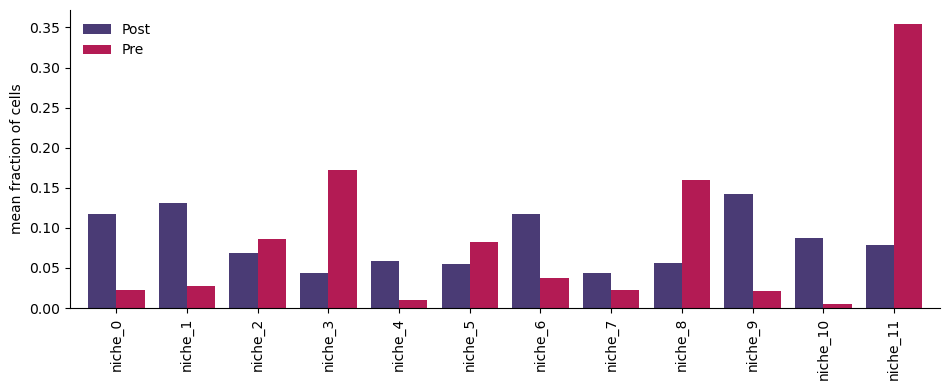

In [21]:
comp = pd.DataFrame(Xc, columns=[f"niche_{i}" for i in range(COMP_NUM_NICHES)])
comp["timepoint"] = [l["timepoint"] for l in kept]
comp["sample_id"] = [l["sample_id"] for l in kept]

by_tp = comp.groupby("timepoint")[
    [c for c in comp.columns if c.startswith("niche_")]
].mean()
print(by_tp.round(3).to_string())

fig, ax = plt.subplots(figsize=(1.2 + 0.7 * COMP_NUM_NICHES, 4))
by_tp.T.plot(kind="bar", ax=ax, color=["#4A3B75", "#B31B54"], width=0.8)
ax.set_ylabel("mean fraction of cells")
ax.set_xlabel("")
ax.legend(title="", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
for ext in (".svg", ".png"):
    fig.savefig((OUT_DIR / "composition_by_timepoint").with_suffix(ext),
                bbox_inches="tight", dpi=200 if ext == ".png" else None)
plt.show()

Two things to hold onto when reading that, and anything built on it.

Sections from the same patient before and after treatment are paired, not
independent, so a test that treats them as independent samples overstates
what the data supports. Collapse to the patient, or use a paired test.

And the flat block has `n_niches x n_shared` columns against a sample count
in the dozens, so it is far wider than it is tall. Cross-validation without
patient grouping will be optimistic, and the standardisation above uses the
whole cohort, so it has to move inside the fold before any reported number
means anything.

In [22]:
def zscore_rows(A):
    """z-score each sample across edges, giving relative prominence."""
    mu = A.mean(1, keepdims=True)
    sd = A.std(1, keepdims=True)
    sd[sd < 1e-8] = 1.0
    return (A - mu) / sd


def patient_deltas(A, sids, meta):
    """Collapse crops to one vector per (patient, timepoint), then take
    Post minus Pre per patient. A may be [S, E] or [S, niche, E]; the
    trailing shape is preserved. Only patients with both timepoints kept."""
    m = meta.set_index("sample_id")
    recs = []
    for i, sid in enumerate(sids):
        if sid not in m.index:
            print(f"  [warn] {sid} not in metadata, skipped")
            continue
        r = m.loc[sid]
        recs.append((str(r.patient_id), str(r.timepoint).capitalize(), i))
    df = pd.DataFrame(recs, columns=["patient", "timepoint", "row"])

    patients, D = [], []
    for pid, sub in df.groupby("patient", sort=True):
        if not {"Pre", "Post"} <= set(sub.timepoint):
            print(f"  [info] {pid}: only {sorted(set(sub.timepoint))}, excluded")
            continue
        post = A[sub[sub.timepoint == "Post"].row.values].mean(0)
        pre  = A[sub[sub.timepoint == "Pre"].row.values].mean(0)
        D.append(post - pre)
        patients.append(pid)
        print(f"  {pid}: {(sub.timepoint == 'Pre').sum()} Pre + "
              f"{(sub.timepoint == 'Post').sum()} Post -> 1 paired delta")

    if not patients:
        raise RuntimeError("No patient had both timepoints.")
    return patients, np.stack(D, axis=0)


def rank_edges(patients, D, edge_labels):
    P = len(patients)
    mean_d = D.mean(0)
    sign_mean = np.sign(mean_d)
    n_agree = (np.sign(D) == sign_mean).sum(0)

    out = pd.DataFrame({
        "edge": edge_labels,
        "mean_delta": mean_d,
        "sd_delta": D.std(0),
        "n_agree": n_agree,
        "n_patients": P,
        "consistency": n_agree / P,
        "all_agree": n_agree == P,
        "direction": np.where(sign_mean >= 0, "up_post", "down_post"),
    })
    for j, pid in enumerate(patients):
        out[f"d_{pid}"] = D[j, :]

    return out.sort_values(
        ["n_agree", "mean_delta"],
        key=lambda s: s.abs() if s.name == "mean_delta" else s,
        ascending=[False, False],
    ).reset_index(drop=True)

In [23]:
# Pairing needs patient_id and timepoint per sample. label_df has them if
# both were read in section 2; otherwise point at the metadata file.
METADATA_CSV = ("/DATA1/Roxana/Hierarchy/B Cell Receptor Diversity/"
                "treatment_pre_post/metadata.csv")

if {"patient_id", "timepoint"} <= set(label_df.columns):
    meta = label_df
else:
    meta = pd.read_csv(METADATA_CSV)
print(f"metadata for {len(meta)} samples")

USE_ZSCORE = True

d = np.load(OUT_DIR / "skin_attention.npz", allow_pickle=True)
A = np.asarray(d["attention"], dtype=float)
sids = [str(s) for s in np.asarray(d["sample_ids"]).ravel()]
edge_labels_attn = [str(e) for e in np.asarray(d["edge_labels"]).ravel()]
print(f"{A.shape[0]} samples x {A.shape[1]} shared edges")

if USE_ZSCORE:
    A = zscore_rows(A)

print("\ncollapsing to patient level:")
patients, D = patient_deltas(A, sids, meta)
print(f"\npaired patients (n={len(patients)}): {patients}")

table = rank_edges(patients, D, edge_labels_attn)
table.to_csv(OUT_DIR / "grn_pre_post_delta.csv", index=False)

print(f"\n{int(table.all_agree.sum())} edges move the same direction in all "
      f"{len(patients)} patients\n")
print(table[["edge", "mean_delta", "n_agree", "consistency", "direction"]]
      .head(15).to_string(index=False))

metadata for 12 samples
12 samples x 735 shared edges

collapsing to patient level:
  su001: 2 Pre + 6 Post -> 1 paired delta
  su002: 1 Pre + 1 Post -> 1 paired delta
  su007: 1 Pre + 1 Post -> 1 paired delta

paired patients (n=3): ['su001', 'su002', 'su007']

612 edges move the same direction in all 3 patients

         edge  mean_delta  n_agree  consistency direction
  TNF->HSPA1B   -1.649911        3          1.0 down_post
   GJB6->GJB2   -1.412045        3          1.0 down_post
   IFNG->CD74    1.242530        3          1.0   up_post
   IL2RA->TXN   -0.931004        3          1.0 down_post
 NOTCH1->KLF4   -0.879604        3          1.0 down_post
  CXCR4->CD74    0.861432        3          1.0   up_post
    TP63->SFN    0.860761        3          1.0   up_post
DUSP1->HSPA1B   -0.798313        3          1.0 down_post
 COL6A1->SDC1   -0.650352        3          1.0 down_post
   MYLK->MYL9    0.608917        3          1.0   up_post
    IFNG->TXN   -0.555600        3          1.

In [24]:
from scipy.stats import spearmanr
from hebi.model.grn_layer import GRNRefinementLayer

# 1. Is attention just 1/in_degree?
#    Attention is normalised over each target's incoming edges, so an
#    untrained layer sits at an even split. Deviation from that split is
#    the only place a learned signal can live.
for i, (rid, attn) in enumerate(zip(sample_ids, ctx["grn_attention"])):
    if attn is None:
        continue
    a = attn.detach().cpu().numpy().ravel()
    tgt = gene_graph_list[i]["global"].edge_index[1].cpu().numpy()
    indeg = np.bincount(tgt, minlength=tgt.max() + 1)[tgt].astype(float)
    u = 1.0 / indeg
    comp = indeg > 1
    r2 = np.corrcoef(a[comp], u[comp])[0, 1] ** 2
    rel = np.median(np.abs(a[comp] - u[comp]) / u[comp])
    print(f"{rid:<28} R2 vs uniform {r2:.4f}   median rel dev {100*rel:5.1f}%")

su001_Post_PostTumor1_rep2   R2 vs uniform 0.6002   median rel dev  55.4%
su001_Post_PostTumor2_rep2   R2 vs uniform 0.6163   median rel dev  55.4%
su001_Post_PostTumor3_rep2   R2 vs uniform 0.6203   median rel dev  54.5%
su001_Post_PostTumor4_rep2   R2 vs uniform 0.6231   median rel dev  57.7%
su001_Post_PostTumor5_rep2   R2 vs uniform 0.6039   median rel dev  53.7%
su001_Post_PostTumor6_rep2   R2 vs uniform 0.5782   median rel dev  55.0%
su001_Pre_PreTumor1_rep2     R2 vs uniform 0.6105   median rel dev  55.3%
su001_Pre_PreTumor2_rep2     R2 vs uniform 0.6080   median rel dev  53.7%
su002_Post_Tumor_GSM8831646  R2 vs uniform 0.6122   median rel dev  53.0%
su002_Pre_Tumor_GSM8831645   R2 vs uniform 0.5901   median rel dev  53.4%
su007_Post_Tumor_GSM8831638  R2 vs uniform 0.6092   median rel dev  54.6%
su007_Pre_Tumor_GSM8831647   R2 vs uniform 0.5697   median rel dev  55.0%


In [25]:
# 2. Did training move the layer at all?
#    Same weights, same input, against a freshly built layer.
trainer = ctx["trainer"]
gg = gene_graph_list[0]["global"].edge_index.to(trainer.device)

with torch.no_grad():
    ge = trainer.gene_embedder(trainer.gene_ids.to(trainer.device))
    ge = trainer.gene_linear(ge)
    ge = torch.nn.functional.normalize(ge, dim=1, p=2)

    trained = trainer.grn_layer(ge, gg, return_attention=True)[1].cpu()
    for seed in (0, 1):
        torch.manual_seed(seed)
        fresh = GRNRefinementLayer(128, 4).to(trainer.device)
        untrained = fresh(ge, gg, return_attention=True)[1].cpu()
        print(f"spearman trained vs untrained (seed {seed}): "
              f"{spearmanr(trained, untrained).statistic:.4f}")

spearman trained vs untrained (seed 0): 0.4891
spearman trained vs untrained (seed 1): 0.5492


In [26]:
# 3. Does it prefer curated edges over co-expression ones?
#    rel = attention x in_degree, which is 1.0 for an even split, so it is
#    comparable across targets with different numbers of competitors.
import pandas as pd

g = gene_graph_list[0]["global"]
ei = g.edge_index.cpu().numpy()
attr = g.edge_attr.cpu().numpy()
a = ctx["grn_attention"][0].detach().cpu().numpy().ravel()
indeg = np.bincount(ei[1], minlength=ei[1].max() + 1)[ei[1]].astype(float)

names = ["pathway", "spearman", "ligrec", "tf_target"]
tier = np.where(attr[:, [0, 2, 3]].any(1),
                np.where(attr[:, 1] > 0, "prior+data", "prior_only"),
                "data_only")

df = pd.DataFrame({"rel": a * indeg, "tier": tier, "in_degree": indeg})
print(df[df.in_degree > 1].groupby("tier")["rel"].agg(["count", "mean", "median"]))

            count      mean    median
tier                                 
data_only     248  1.014374  0.739339
prior+data      3  0.858855  0.589838
prior_only    690  0.995447  0.752166


In [28]:
# Is the between-sample variation larger than the noise floor?
# su001 has 6 Post crops from the same patient and timepoint. Differences
# among those are technical, so they bound what counts as a real shift.
import re
A = np.load(OUT_DIR / "skin_attention.npz", allow_pickle=True)
Araw, sids = A["attention"], [str(s) for s in A["sample_ids"]]

post1 = [i for i, s in enumerate(sids) if s.startswith("su001_Post")]
pre1   = [i for i, s in enumerate(sids) if s.startswith("su001_Pre")]
print("within su001 Post crops, mean sd per edge: %.4f" % Araw[post1].std(0).mean())
print("su001 Post minus Pre, mean |delta| per edge: %.4f"
      % np.abs(Araw[post1].mean(0) - Araw[pre1].mean(0)).mean())

within su001 Post crops, mean sd per edge: 0.0126
su001 Post minus Pre, mean |delta| per edge: 0.0196


In [29]:
for drop in patients:
    keep = [j for j, p in enumerate(patients) if p != drop]
    sub = rank_edges([patients[j] for j in keep], D[keep], edge_labels_attn)
    print(f"without {drop}: {len(set(sub.edge.head(10)) & set(table.edge.head(10)))}/10 kept")

without su001: 6/10 kept
without su002: 6/10 kept
without su007: 6/10 kept


In [30]:
stable = set(table.edge.head(10))
for drop in patients:
    keep = [j for j, p in enumerate(patients) if p != drop]
    sub = rank_edges([patients[j] for j in keep], D[keep], edge_labels_attn)
    stable &= set(sub.edge.head(10))

core = table[table.edge.isin(stable)]
core = core[core.mean_delta.abs() > 0.0126]     # بالاتر از کف نویز
print(f"{len(core)} edges: in the top 10 of every leave-one-out, "
      f"and above the technical noise floor\n")
print(core[["edge", "mean_delta", "n_agree", "consistency", "direction"]]
      .to_string(index=False))

2 edges: in the top 10 of every leave-one-out, and above the technical noise floor

       edge  mean_delta  n_agree  consistency direction
TNF->HSPA1B   -1.649911        3          1.0 down_post
 IFNG->CD74    1.242530        3          1.0   up_post


In [31]:
print(table[table.edge.isin(["TNF->HSPA1B", "IFNG->CD74"])].to_string(index=False))

       edge  mean_delta  sd_delta  n_agree  n_patients  consistency  all_agree direction   d_su001   d_su002   d_su007
TNF->HSPA1B   -1.649911  0.561144        3           3          1.0       True down_post -1.343016 -2.437146 -1.169571
 IFNG->CD74    1.242530  0.197564        3           3          1.0       True   up_post  0.964626  1.406477  1.356486


In [34]:
dcols = [c for c in table.columns if c.startswith("d_")]

for c in dcols:
    pid = c[2:]
    sub = table.reindex(table[c].abs().sort_values(ascending=False).index)
    print(f"\n=== {pid}: largest Pre to Post shifts ===")
    print(sub[["edge", c, "n_agree"]].head(10).to_string(index=False))


=== su001: largest Pre to Post shifts ===
         edge   d_su001  n_agree
   GJB6->GJB2 -3.141658        3
  TP63->KRT14 -2.694019        2
   GJB2->GJB6 -2.313400        2
PIK3R1->GNG11  1.806037        1
   JUN->KRT17 -1.791623        1
   MYLK->MYL9  1.750960        3
   FOS->KRT17 -1.506965        1
   TP63->KRT5 -1.462293        2
 MMP1->S100A8  1.427542        1
CD4->HLA-DQB1 -1.365856        1

=== su002: largest Pre to Post shifts ===
         edge   d_su002  n_agree
   GJB2->GJB6  3.692406        2
PIK3R1->GNG11 -3.592594        1
  IL1B->PTGDS -3.250821        2
  TNF->HSPA1B -2.437146        3
   IFNG->TYMS -2.213385        1
   IFNG->TGFA  2.037722        2
  TP63->TOP2A -1.989283        2
    TP63->SFN  1.752750        3
    FOS->TGFA  1.730924        2
   CD4->PTPRC -1.434918        1

=== su007: largest Pre to Post shifts ===
         edge   d_su007  n_agree
   GJB2->GJB6  3.864212        2
  IL1B->PTGDS -3.317947        2
CCND1->CDKN2B -2.873323        2
   JUN->STMN1

In [35]:
D_ = table[dcols].to_numpy()
disagree = (np.sign(D_) != np.sign(D_[:, [0]])).sum(1)     # نسبت به بیمار اول
table["spread"] = D_.max(1) - D_.min(1)

print(table.reindex(table.spread.sort_values(ascending=False).index)
      [["edge"] + dcols + ["spread"]].head(15).to_string(index=False))

         edge   d_su001   d_su002   d_su007   spread
   GJB2->GJB6 -2.313400  3.692406  3.864212 6.177612
PIK3R1->GNG11  1.806037 -3.592594  0.009282 5.398631
   IFNG->TGFA  0.920636  2.037722 -1.985052 4.022775
  IL1B->PTGDS  0.079099 -3.250821 -3.317947 3.397045
    FOS->TGFA  0.814263  1.730924 -1.664153 3.395077
   GJB6->GJB2 -3.141658 -1.068871 -0.025607 3.116051
CCND1->CDKN2B -0.341248  0.032441 -2.873323 2.905764
   JUN->STMN1 -0.852903  0.951688  2.043042 2.895945
  TP63->KRT14 -2.694019 -0.190497  0.166198 2.860216
   CD2->STMN1 -0.766898  1.113733  1.946224 2.713122
   TP63->KRT5 -1.462293  0.754862  1.027372 2.489665
  MMP2->CLDN1 -1.072631  1.411759 -0.500897 2.484390
   JUN->KRT17 -1.791623  0.549942  0.526791 2.341565
   IFNG->TYMS  0.079099 -2.213385  0.009282 2.292484
CD4->HLA-DQA1 -1.153120  0.047050  1.076131 2.229251


In [36]:
for g in ["IFNG", "TNF", "IL1B", "GJB6"]:
    a = sections[0]
    if g in a.var_names:
        x = a[:, g].X
        x = x.toarray().ravel() if hasattr(x, "toarray") else np.asarray(x).ravel()
        print(f"{g:<8} {(x > 0).mean():>6.2%} of cells non-zero")

IFNG      0.84% of cells non-zero
TNF       1.11% of cells non-zero
IL1B      0.60% of cells non-zero
GJB6     57.74% of cells non-zero


su001: 2 Pre, 6 Post sections


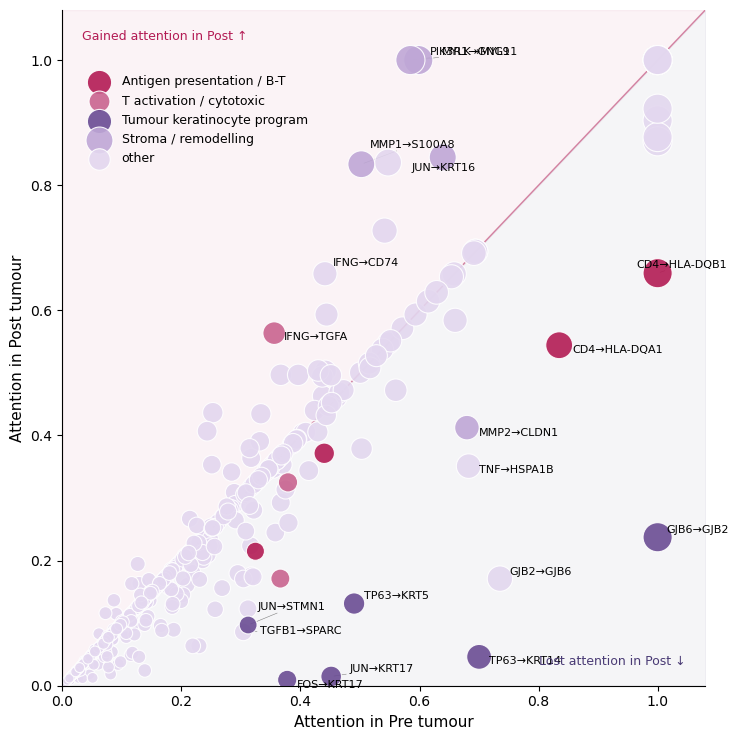

         edge      pre     post     delta                       group
   GJB6->GJB2 1.000000 0.237339 -0.762661 Tumour keratinocyte program
  TP63->KRT14 0.700128 0.046114 -0.654014 Tumour keratinocyte program
   GJB2->GJB6 0.735100 0.171177 -0.563923                       other
   JUN->KRT17 0.451555 0.014767 -0.436788 Tumour keratinocyte program
PIK3R1->GNG11 0.584691 1.000000  0.415309        Stroma / remodelling
   MYLK->MYL9 0.597937 1.000000  0.402063        Stroma / remodelling
   FOS->KRT17 0.377666 0.009333 -0.368333 Tumour keratinocyte program
   TP63->KRT5 0.490044 0.131345 -0.358699 Tumour keratinocyte program
CD4->HLA-DQB1 1.000000 0.659361 -0.340639  Antigen presentation / B-T
  TNF->HSPA1B 0.682470 0.350992 -0.331478                       other
 MMP1->S100A8 0.502187 0.833511  0.331325        Stroma / remodelling
CD4->HLA-DQA1 0.834634 0.544223 -0.290411  Antigen presentation / B-T
   JUN->KRT16 0.547117 0.836185  0.289067                       other
  MMP2->CLDN1 0.6796

In [37]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from adjustText import adjust_text     # pip install adjustText

mpl.rcParams.update({"font.family": "DejaVu Sans", "svg.fonttype": "none"})

# --- edit: which patient, and how the edges group -----------------------
PATIENT = "su001"
GROUPS = {
    "Antigen presentation / B-T": ["CD4->HLA-DQB1", "CD4->HLA-DQA1",
                                   "CD4->HLA-DRA", "CXCL13->S100A2"],
    "T activation / cytotoxic":   ["IFNG->TGFA", "CD2->STMN1", "IL2RA->TXN"],
    "Tumour keratinocyte program":["GJB6->GJB2", "TP63->KRT14", "TP63->KRT5",
                                   "JUN->KRT17", "JUN->STMN1", "FOS->KRT17"],
    "Stroma / remodelling":       ["PIK3R1->GNG11", "MYLK->MYL9", "MMP1->S100A8",
                                   "TGFB1->TAGLN", "MMP2->CLDN1"],
}
COLOURS = {"Antigen presentation / B-T": "#B31B54",
           "T activation / cytotoxic":   "#C9648F",
           "Tumour keratinocyte program":"#6A4C93",
           "Stroma / remodelling":       "#BFA7D6",
           "other":                      "#E3D7EF"}
N_LABEL = 18          # how many edges to annotate
# ------------------------------------------------------------------------

d = np.load(OUT_DIR / "skin_attention.npz", allow_pickle=True)
A = np.asarray(d["attention"], float)
sids = [str(s) for s in d["sample_ids"]]
elab = [str(e) for e in np.asarray(d["edge_labels"]).ravel()]

m = meta.set_index("sample_id")
rows = {"Pre": [], "Post": []}
for i, s in enumerate(sids):
    if s not in m.index or str(m.loc[s].patient_id) != PATIENT:
        continue
    rows[str(m.loc[s].timepoint).capitalize()].append(i)
print(f"{PATIENT}: {len(rows['Pre'])} Pre, {len(rows['Post'])} Post sections")

pre  = A[rows["Pre"]].mean(0)
post = A[rows["Post"]].mean(0)

group_of = {e: g for g, es in GROUPS.items() for e in es}
df = pd.DataFrame({"edge": elab, "pre": pre, "post": post})
df["group"] = df.edge.map(group_of).fillna("other")
df["delta"] = df.post - df.pre
df["size"]  = 40 + 400 * (df[["pre", "post"]].max(1) /
                          df[["pre", "post"]].max(1).max())

fig, ax = plt.subplots(figsize=(7.5, 7.5))
lim = max(df.pre.max(), df.post.max()) * 1.08

# Shaded halves say the direction without needing the reader to work out
# which side of the diagonal means what.
ax.fill_between([0, lim], [0, lim], [lim, lim], color="#B31B54", alpha=0.05)
ax.fill_between([0, lim], [0, 0], [0, lim], color="#4A3B75", alpha=0.05)
ax.plot([0, lim], [0, lim], color="#B31B54", lw=1, alpha=0.5)

for g in list(GROUPS) + ["other"]:
    s = df[df.group == g]
    ax.scatter(s.pre, s.post, s=s["size"], c=COLOURS[g], label=g,
               edgecolor="white", linewidth=0.8, alpha=0.9,
               zorder=3 if g != "other" else 2, rasterized=True)

top = df.reindex(df.delta.abs().sort_values(ascending=False).index).head(N_LABEL)
texts = [ax.text(r.pre, r.post, r.edge.replace("->", "→"), fontsize=8)
         for _, r in top.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", lw=0.4, color="grey"))

ax.text(0.03, 0.97, "Gained attention in Post ↑", transform=ax.transAxes,
        fontsize=9, color="#B31B54", va="top")
ax.text(0.97, 0.03, "Lost attention in Post ↓", transform=ax.transAxes,
        fontsize=9, color="#4A3B75", ha="right")

ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Attention in Pre tumour", fontsize=11)
ax.set_ylabel("Attention in Post tumour", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0.02, 0.92))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

for ext in (".svg", ".png"):
    fig.savefig((OUT_DIR / f"grn_pre_post_{PATIENT}").with_suffix(ext),
                bbox_inches="tight", dpi=300 if ext == ".png" else None)
plt.show()

print(top[["edge", "pre", "post", "delta", "group"]].to_string(index=False))

In [38]:
PATIENT = "su001"
N_TOP = 20

d = np.load(OUT_DIR / "skin_attention.npz", allow_pickle=True)
A = np.asarray(d["attention"], float)
sids = [str(s) for s in d["sample_ids"]]
elab = [str(e) for e in np.asarray(d["edge_labels"]).ravel()]

m = meta.set_index("sample_id")
rows = {"Pre": [], "Post": []}
for i, s in enumerate(sids):
    if s in m.index and str(m.loc[s].patient_id) == PATIENT:
        rows[str(m.loc[s].timepoint).capitalize()].append(i)
print(f"{PATIENT}: {len(rows['Pre'])} Pre, {len(rows['Post'])} Post\n")

df = pd.DataFrame({
    "edge": elab,
    "pre":  A[rows["Pre"]].mean(0),
    "post": A[rows["Post"]].mean(0),
})
df["delta"] = df.post - df.pre

# detection rate, so a shift on a gene seen in <1% of cells is visible as such
a0 = sections[0]
det = {}
for g in {g for e in df.edge for g in e.split("->")}:
    if g in a0.var_names:
        x = a0[:, g].X
        x = x.toarray().ravel() if hasattr(x, "toarray") else np.asarray(x).ravel()
        det[g] = (x > 0).mean()
df["min_detect"] = [min(det.get(g, np.nan) for g in e.split("->")) for e in df.edge]

top = df.reindex(df.delta.abs().sort_values(ascending=False).index).head(N_TOP)
top["dir"] = np.where(top.delta > 0, "up_post", "down_post")
print(top[["edge", "pre", "post", "delta", "dir", "min_detect"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

su001: 2 Pre, 6 Post

         edge   pre  post  delta       dir  min_detect
   GJB6->GJB2 1.000 0.237 -0.763 down_post       0.577
  TP63->KRT14 0.700 0.046 -0.654 down_post       0.468
   GJB2->GJB6 0.735 0.171 -0.564 down_post       0.577
   JUN->KRT17 0.452 0.015 -0.437 down_post       0.263
PIK3R1->GNG11 0.585 1.000  0.415   up_post       0.039
   MYLK->MYL9 0.598 1.000  0.402   up_post       0.192
   FOS->KRT17 0.378 0.009 -0.368 down_post       0.110
   TP63->KRT5 0.490 0.131 -0.359 down_post       0.468
CD4->HLA-DQB1 1.000 0.659 -0.341 down_post       0.047
  TNF->HSPA1B 0.682 0.351 -0.331 down_post       0.011
 MMP1->S100A8 0.502 0.834  0.331   up_post       0.012
CD4->HLA-DQA1 0.835 0.544 -0.290 down_post       0.047
   JUN->KRT16 0.547 0.836  0.289   up_post       0.101
  MMP2->CLDN1 0.680 0.412 -0.267 down_post       0.337
 TGFB1->SPARC 0.304 0.086 -0.218 down_post       0.094
   IFNG->CD74 0.441 0.658  0.217   up_post       0.008
   JUN->STMN1 0.312 0.097 -0.215 down_post 

In [39]:
for e in ["GJB6->GJB2", "PIK3R1->GNG11", "MYLK->MYL9", "CD4->HLA-DQB1"]:
    tgt = e.split("->")[1]
    for tp, idxs in rows.items():
        i = idxs[0]
        ei = gene_graph_list[i]["global"].edge_index.cpu().numpy()
        n = sum(1 for u, v in zip(ei[0], ei[1]) if gene_names[v] == tgt)
        print(f"{e:<16} {tp:<5} in-degree of {tgt}: {n}")

GJB6->GJB2       Pre   in-degree of GJB2: 1
GJB6->GJB2       Post  in-degree of GJB2: 10
PIK3R1->GNG11    Pre   in-degree of GNG11: 1
PIK3R1->GNG11    Post  in-degree of GNG11: 1
MYLK->MYL9       Pre   in-degree of MYL9: 1
MYLK->MYL9       Post  in-degree of MYL9: 1
CD4->HLA-DQB1    Pre   in-degree of HLA-DQB1: 1
CD4->HLA-DQB1    Post  in-degree of HLA-DQB1: 3


In [43]:
i = rows["Pre"][0]
a = A[i]
ei = gene_graph_list[i]["global"].edge_index.cpu().numpy()
indeg = np.bincount(ei[1], minlength=ei[1].max() + 1)[ei[1]].astype(float)[positions[i]]

print("shared edges:", len(a), " in_degree==1 among them:", int((indeg == 1).sum()))
print("their attention:", np.unique(a[indeg == 1].round(3))[:10])

shared edges: 735  in_degree==1 among them: 38
their attention: [1.]


In [42]:
def rel_attention(A_row, graph, pos):
    """attention relative to an even split among the target's regulators.
    A_row is already restricted to the shared edges, so the in-degree has
    to be sliced by the same positions."""
    ei = graph["global"].edge_index.cpu().numpy()
    indeg = np.bincount(ei[1], minlength=ei[1].max() + 1)[ei[1]].astype(float)
    return A_row * indeg[pos]


pre_rel  = np.mean([rel_attention(A[i], gene_graph_list[i], positions[i])
                    for i in rows["Pre"]], 0)
post_rel = np.mean([rel_attention(A[i], gene_graph_list[i], positions[i])
                    for i in rows["Post"]], 0)

df2 = pd.DataFrame({"edge": elab, "pre": pre_rel, "post": post_rel})
df2["delta"] = df2.post - df2.pre
df2["min_detect"] = df["min_detect"].values

print(df2.reindex(df2.delta.abs().sort_values(ascending=False).index)
      .head(20).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

            edge   pre  post  delta  min_detect
      JUN->KRT17 1.085 0.244 -0.841       0.263
      FOS->KRT17 0.903 0.156 -0.746       0.110
PIK3R1->HLA-DRB1 1.314 0.589 -0.725       0.077
   CXCR3->CXCL14 1.559 0.890 -0.669       0.003
     TP63->KRT14 1.100 0.549 -0.551       0.468
    TGFB1->SPARC 1.253 0.731 -0.522       0.094
     CCL17->TP63 1.679 2.177  0.499       0.000
      JUN->SPARC 0.970 0.482 -0.488       0.263
      JUN->STMN1 0.831 0.387 -0.444       0.263
   COL6A2->ITGA6 0.707 1.144  0.437       0.228
    S100A2->TP63 1.845 2.252  0.407       0.229
  FYB1->HLA-DRB1 1.540 1.161 -0.378       0.043
   FOS->HLA-DRB1 0.773 0.427 -0.346       0.077
   CD86->HLA-DRA 0.787 0.451 -0.336       0.026
      CD2->STMN1 1.061 1.387  0.326       0.039
    FOS->HLA-DRA 0.809 0.485 -0.324       0.110
      IFNG->CD74 0.994 1.317  0.323       0.008
    MMP1->S100A8 0.522 0.840  0.318       0.012
      MYLK->MYL9 0.696 1.000  0.304       0.192
      GJB6->GJB2 1.000 1.297  0.297     

In [44]:
# rel برای همه نمونه‌ها، نه فقط su001
A_rel = np.stack([
    rel_attention(A[i], gene_graph_list[i], positions[i])
    for i in range(len(sids))
])

A_relz = zscore_rows(A_rel)
patients2, D2 = patient_deltas(A_relz, sids, meta)
table2 = rank_edges(patients2, D2, elab)

# کف نویز، در همان فضا
post1 = [i for i, s in enumerate(sids) if s.startswith("su001_Post")]
noise = A_relz[post1].std(0).mean()
print(f"technical noise floor: {noise:.4f}\n")

# سه فیلتر قبلی، روی مبنای درست
stable = set(table2.edge.head(10))
for drop in patients2:
    keep = [j for j, p in enumerate(patients2) if p != drop]
    sub = rank_edges([patients2[j] for j in keep], D2[keep], elab)
    stable &= set(sub.edge.head(10))

core = table2[table2.edge.isin(stable) & (table2.mean_delta.abs() > noise)]
print(f"{len(core)} edges pass all three filters:\n")
print(core[["edge", "mean_delta", "n_agree", "direction"]].to_string(index=False))

print("\ntop 20 by |mean_delta|:")
print(table2.reindex(table2.mean_delta.abs().sort_values(ascending=False).index)
      .head(20)[["edge", "mean_delta", "n_agree"] +
                [c for c in table2.columns if c.startswith("d_")]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

  su001: 2 Pre + 6 Post -> 1 paired delta
  su002: 1 Pre + 1 Post -> 1 paired delta
  su007: 1 Pre + 1 Post -> 1 paired delta
technical noise floor: 0.0448

4 edges pass all three filters:

        edge  mean_delta  n_agree direction
 IL1B->PTGDS    1.004116        3   up_post
COL9A2->SDC1   -0.644115        3 down_post
  IL2RA->TXN   -0.530268        3 down_post
 TNF->HSPA1B   -0.438302        3 down_post

top 20 by |mean_delta|:
         edge  mean_delta  n_agree  d_su001  d_su002  d_su007
  IL1B->PTGDS       1.004        3    0.008    1.339    1.665
 COL9A2->SDC1      -0.644        3   -0.039   -0.933   -0.961
   IL2RA->TXN      -0.530        3   -0.141   -0.559   -0.891
   TP63->KRT5       0.498        2   -0.027    0.902    0.619
   GJB6->GJB2      -0.481        2    0.336   -1.045   -0.733
 COL4A1->SDC1      -0.477        2    0.026   -0.708   -0.748
  TNF->HSPA1B      -0.438        3   -0.135   -0.579   -0.602
     JUN->TXN      -0.417        3   -0.098   -0.572   -0.581
 IL2RA-

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from adjustText import adjust_text

mpl.rcParams.update({"font.family": "DejaVu Sans", "svg.fonttype": "none"})

GROUPS = {
    "Keratinocyte differentiation": [
        "JUN->KRT17", "FOS->KRT17", "TP63->KRT14", "S100A2->TP63", "GJB6->GJB2"],
    "MHC class II": [
        "PIK3R1->HLA-DRB1", "FYB1->HLA-DRB1", "FOS->HLA-DRB1",
        "FOS->HLA-DRA", "CD86->HLA-DRA", "IFNG->CD74"],
    "Stroma / matrix": [
        "TGFB1->SPARC", "JUN->SPARC", "COL6A2->ITGA6",
        "MMP1->S100A8", "MYLK->MYL9"],
    "T cell / proliferation": ["CD2->STMN1", "JUN->STMN1"],
}
COLOURS = {"Keratinocyte differentiation": "#6A4C93",
           "MHC class II":                 "#B31B54",
           "Stroma / matrix":              "#BFA7D6",
           "T cell / proliferation":       "#C9648F",
           "other":                        "#E3D7EF"}

MIN_DETECT = 0.01      # drop edges whose genes are essentially undetected
N_LABEL    = 18

p = df2[df2.min_detect >= MIN_DETECT].copy()
p = p.reindex(p.delta.abs().sort_values(ascending=False).index).head(20)
p["group"] = p.edge.map({e: g for g, es in GROUPS.items() for e in es}).fillna("other")
p["size"]  = 40 + 360 * (p[["pre", "post"]].max(1) / p[["pre", "post"]].max(1).max())
fig, ax = plt.subplots(figsize=(7.5, 7.5))
lim = max(p.pre.max(), p.post.max()) * 1.08
ax.fill_between([0, lim], [0, lim], [lim, lim], color="#B31B54", alpha=0.05)
ax.fill_between([0, lim], [0, 0],   [0, lim],   color="#4A3B75", alpha=0.05)
ax.plot([0, lim], [0, lim], color="#B31B54", lw=1, alpha=0.5)
ax.axhline(1, color="grey", lw=0.5, ls=":")     # 1.0 = an even split
ax.axvline(1, color="grey", lw=0.5, ls=":")

for g in list(GROUPS) + ["other"]:
    s = p[p.group == g]
    ax.scatter(s.pre, s.post, s=s["size"], c=COLOURS[g], label=g,
               edgecolor="white", linewidth=0.8, alpha=0.9,
               zorder=3 if g != "other" else 2, rasterized=True)

top = p
texts = [ax.text(r.pre, r.post, r.edge.replace("->", "→"), fontsize=11)
         for _, r in top.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", lw=0.4, color="grey"))

ax.text(0.03, 0.97, "Gained attention in post ↑", transform=ax.transAxes,
        fontsize=12, color="#B31B54", va="top")
ax.text(0.97, 0.03, "Lost attention in post ↓", transform=ax.transAxes,
        fontsize=12, color="#4A3B75", ha="right")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("Attention in Pre tumour", fontsize=15)
ax.set_ylabel("Attention in Post tumour", fontsize=15)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0.02, 0.93))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

for ext in (".svg", ".png"):
    fig.savefig((OUT_DIR / "grn_pre_post_su001").with_suffix(ext),
                bbox_inches="tight", dpi=300 if ext == ".png" else None)
plt.show()

print(f"{len(df2) - len(p)} edges dropped below {MIN_DETECT:.0%} detection")
print(top[["edge", "pre", "post", "delta", "group", "min_detect"]]
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

NameError: name 'df2' is not defined

In [52]:
print(len(elab), "edges in the loaded attention file")
print(sorted(set(sids)))

735 edges in the loaded attention file
['su001_Post_PostTumor1_rep2', 'su001_Post_PostTumor2_rep2', 'su001_Post_PostTumor3_rep2', 'su001_Post_PostTumor4_rep2', 'su001_Post_PostTumor5_rep2', 'su001_Post_PostTumor6_rep2', 'su001_Pre_PreTumor1_rep2', 'su001_Pre_PreTumor2_rep2', 'su002_Post_Tumor_GSM8831646', 'su002_Pre_Tumor_GSM8831645', 'su007_Post_Tumor_GSM8831638', 'su007_Pre_Tumor_GSM8831647']
